# U² field & NH motion
저장된 실험의 특정 iteration에서 **고정된 GP 위의 NH 이동**을 재현합니다.

- 전체 U² 지형 → 국소 확대와 힘 방향 → Hamiltonian 에너지 → 재생 가능한 이동 → 관측 전후 필드 변화를 확인합니다.
- 기본값은 마지막 L-BFGS-B child가 있는 iteration입니다. `ITERATION`을 바꾸고 Run All 하면 다른 시점을 봅니다.
- 원본에는 전체 궤적이 저장되지 않았으므로 **현재 코드로 재현한 경로**입니다. 기록된 theta와 그때까지의 학습 데이터만 사용하며, 최종 모델을 과거 시점에 사용하지 않습니다.
- 실제 경로와 일치하는지 선택점·U값·진단 횟수를 검증합니다. 불일치하면 실행을 중단합니다.
- 애니메이션의 프레임은 계산 이벤트 순서입니다. Hamiltonian step과 L-BFGS-B 평가점은 서로 다른 종류의 움직임입니다.

환경 설치: `.venv\\Scripts\\python.exe -m pip install -r requirements-visualize.txt`. Jupyter에서 프로젝트 `.venv` 커널을 선택하세요.

In [1]:
from pathlib import Path
import json
import random
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "nh.py").is_file() and (p / "pipeline.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("프로젝트 폴더에서 노트북을 실행하세요.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from adaptive import UAcquisition, BatchedPoolSelector, accept_refinement
from metamodels.ordinary_kriging import OrdinaryKriging
from nh import NestedHamiltonianPrototype
from g import Problem

RUN_DIR = ROOT / "runs/gp_trial_01"
ITERATION = None  # 예: 100, 300, 489. None = 마지막 local-search child iteration
GRID_SIZE = 170
GLOBAL_LIMITS = (-4.0, 4.0, -4.0, 4.0)  # 표시 범위일 뿐 MC 적분 범위 제한이 아님
ZOOM_MIN_HALF_WIDTH = 0.06
LOG_ENERGY_LIMITS = (-6.0, 4.0)  # log10(U²), 범위 밖은 색상 포화
MAKE_ANIMATION = True
EXPORT_DIR = ROOT / "artifacts/visualize"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "animation.embed_limit": 40})
COLORS = {"hmc": "#00a6a6", "child": "#e87924", "reference": "#efc34a", "selected": "#e44eb4"}
norm = Normalize(*LOG_ENERGY_LIMITS)
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))
def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]
def finish(fig, name):
    fig.savefig(EXPORT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 해당 시점의 모델 복원
`selection.snapshot`에 대응하는 evaluation에서 theta와 학습 개수를 읽습니다.
최적화는 다시 하지 않고, 기록된 theta를 고정해 GLS 상태를 재구성합니다.
새 설정의 600회 예산은 앞으로의 run에 적용되며, 여기서는 저장된 run의 설정을 사용합니다.

In [2]:
runs = {}
for mode in ("reference", "nh"):
    folder = RUN_DIR / mode
    runs[mode] = {"folder": folder, "cfg": read_json(folder / "effective_config.json"),
                  "evaluations": read_jsonl(folder / "evaluation.jsonl"),
                  "selections": read_jsonl(folder / "selection.jsonl"),
                  "calls": read_jsonl(folder / "g_calls.jsonl"),
                  "fixed": read_json(folder / "fixed_samples.json")["integration"]}
    assert all(r["status"] == "ok" for r in runs[mode]["calls"])

records = runs["nh"]["selections"]
if ITERATION is None:
    candidates = [r for r in records if r["nh_diagnostics"].get("local_search_paths", 0)]
    record = (candidates or records)[-1]
else:
    record = next(r for r in records if r["iteration"] == ITERATION)
iteration = record["iteration"]
before_row = next(r for r in runs["nh"]["evaluations"] if r["model_snapshot"] == record["snapshot"])

def restore(mode, row):
    run = runs[mode]
    cfg = run["cfg"]
    if cfg["metamodel"]["factory"] != "metamodels.ordinary_kriging:OrdinaryKriging":
        raise ValueError("이 노트북은 기록된 OrdinaryKriging 모델 복원용입니다.")
    n = row["n_true_calls"]
    calls = run["calls"][:n]
    X = np.asarray([r["x"] for r in calls])
    Y = np.asarray([r["y"] for r in calls])
    if X.shape[1] != 2:
        raise ValueError("필드 시각화는 2차원 문제를 대상으로 합니다.")
    model_cfg = dict(cfg["metamodel"], theta=row["training_log"]["theta"], optimize=False)
    model = OrdinaryKriging(model_cfg)
    model.fit(X, Y)
    for key in ("beta", "process_variance", "objective"):
        np.testing.assert_allclose(model.training_log[key], row["training_log"][key],
                                   rtol=1e-7, atol=1e-7, err_msg=f"모델 복원 실패: {key}")
    return model, X, Y

def population(mode, row):
    run = runs[mode]
    n = row["population_size"]
    points = run["fixed"]
    if n > len(points):
        points = read_json(run["folder"] / "mc_population.json")
    if len(points) < n:
        raise ValueError("해당 시점의 확장 MC 모집단을 찾을 수 없습니다.")
    return np.asarray(points[:n], dtype=float)

model, X, Y = restore("nh", before_row)
acquisition = UAcquisition(model)
cfg = runs["nh"]["cfg"]
problem = Problem(cfg["problem"])
pool = population("nh", before_row)
selector = BatchedPoolSelector(cfg["sampling"])
x_ref = np.asarray(record["x_reference"])
x_selected = np.asarray(record["x_selected"])
np.testing.assert_allclose(acquisition.score(x_ref), record["a_reference"], rtol=1e-6, atol=1e-8)
print(f"run={RUN_DIR.name}, NH iteration={iteration}, training calls={len(X)}, pool={len(pool)}")
print(f"recorded budget={cfg['evaluation']['max_true_calls']}; theta={model.theta}")
print(f"U(reference)={record['a_reference']:.6g}, U(selected)={record['a_selected']:.6g}")

run=gp_trial_01, NH iteration=489, training calls=499, pool=60000
recorded budget=500; theta=[7.46426393 7.46426393]
U(reference)=1.27468, U(selected)=6.15302e-09


## 경로 재현과 일치 확인
기록된 seed + 20000 + iteration을 사용합니다. trace는 계산값을 기록할 뿐 난수나 선택 규칙을 바꾸지 않습니다.
Hamiltonian의 거절점은 실제 방문 상태가 아니며 ×로만 표시합니다.
L-BFGS-B 점들은 line search를 포함한 **목적함수 평가 순서**이며, 연속적인 물리 궤적이 아닙니다.

In [3]:
trace = []
proposals, diagnostics = NestedHamiltonianPrototype(cfg["nh"]).refine(
    x_ref.tolist(), acquisition, problem,
    random.Random(int(cfg["seed"]) + 20000 + iteration), trace=trace)
replayed_x, replayed_u = accept_refinement(
    x_ref.tolist(), record["a_reference"], proposals, acquisition,
    lambda x: selector.valid(x, X, problem))
np.testing.assert_allclose(replayed_x, x_selected, atol=1e-7, rtol=1e-7,
                           err_msg="선택점 재현 불일치: 코드/환경 차이를 확인하세요.")
np.testing.assert_allclose(replayed_u, record["a_selected"], atol=1e-7, rtol=1e-5)
for key in ("paths", "branches", "accepted_steps", "rejected_steps", "local_search_paths"):
    assert diagnostics[key] == record["nh_diagnostics"][key], f"경로 진단 불일치: {key}"
hmc_paths = {}
child_paths = {}
for event in trace:
    if event["event"] in ("start", "accepted"):
        hmc_paths.setdefault(event["path"], []).append(event)
    elif event["event"] == "child_evaluation":
        child_paths.setdefault(event["path"], []).append(event)
rejected = [e for e in trace if e["event"] == "rejected"]
print("Replay matches recorded selection and diagnostic counts.")
print({k: diagnostics[k] for k in ("paths", "accepted_steps", "rejected_steps", "local_search_paths")})
motion_points = np.asarray([e["x"] for e in trace if e["event"] != "rejected"] + [x_ref.tolist(), x_selected.tolist()])
center = (motion_points.min(axis=0) + motion_points.max(axis=0)) / 2
half = max(float(np.ptp(motion_points, axis=0).max()) * .7, ZOOM_MIN_HALF_WIDTH)
zoom = (center[0]-half, center[0]+half, center[1]-half, center[1]+half)
events_to_animate = [e for e in trace if e["event"] != "rejected"]

Replay matches recorded selection and diagnostic counts.
{'paths': 2, 'accepted_steps': 15, 'rejected_steps': 4, 'local_search_paths': 1}


In [4]:
def field(model, limits, size=GRID_SIZE):
    x = np.linspace(limits[0], limits[1], size)
    y = np.linspace(limits[2], limits[3], size)
    xx, yy = np.meshgrid(x, y)
    points = np.column_stack([xx.ravel(), yy.ravel()])
    mu, var = model.predict_moments(points)
    energy = mu * mu / var
    return xx, yy, energy.reshape(xx.shape), mu.reshape(xx.shape)

def draw_field(ax, data, title):
    xx, yy, energy, mu = data
    image = ax.pcolormesh(xx, yy, np.log10(np.maximum(energy, 1e-12)),
                         shading="auto", cmap="viridis", norm=norm, rasterized=True)
    if energy.min() < 4 < energy.max():
        ax.contour(xx, yy, energy, levels=[4], colors=[COLORS["reference"]], linewidths=1)
    if mu.min() < 0 < mu.max():
        ax.contour(xx, yy, mu, levels=[0], colors="white", linestyles="--", linewidths=1)
    ax.set(xlabel="x1", ylabel="x2", title=title, xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()))
    ax.set_aspect("equal")
    return image

def markers(ax, training=True):
    if training:
        ax.scatter(X[:, 0], X[:, 1], s=8, c="#cccccc", alpha=.6, marker=".", label="Training")
    ax.scatter(*x_ref, c=COLORS["reference"], marker="*", s=150, edgecolors="black", zorder=6, label="Pool reference")
    ax.scatter(*x_selected, c=COLORS["selected"], marker="D", s=55, edgecolors="black", zorder=7, label="NH selected")

def draw_paths(ax):
    for path, events in hmc_paths.items():
        points = np.array([e["x"] for e in events])
        ax.plot(points[:, 0], points[:, 1], "-o", ms=3, color=COLORS["hmc"], label=f"Hamiltonian {path}")
        if len(points) > 1:
            for a, b in zip(points[:-1], points[1:]):
                ax.annotate("", xy=b, xytext=a, arrowprops={"arrowstyle": "->", "color": COLORS["hmc"], "lw": .8})
    for path, events in child_paths.items():
        points = np.array([e["x"] for e in events])
        ax.scatter(points[:, 0], points[:, 1], s=24, c=COLORS["child"], marker="s", label=f"L-BFGS-B evaluations {path}")
    if rejected:
        points = np.array([e["x"] for e in rejected])
        ax.scatter(points[:, 0], points[:, 1], s=25, c="#ee9999", marker="x", label="Rejected trials")

def colorbar(fig, image, axes):
    fig.colorbar(image, ax=axes, shrink=.85, extend="both", label="log10(U²), clipped color range")

global_data = field(model, GLOBAL_LIMITS)
local_data = field(model, zoom)
accepted_points = np.asarray([e["x"] for e in trace if e["event"] in ("start", "accepted")] + [x_selected.tolist()])
tight_center = (accepted_points.min(axis=0) + accepted_points.max(axis=0)) / 2
tight_half = max(float(np.ptp(accepted_points, axis=0).max()) * .7, ZOOM_MIN_HALF_WIDTH)
tight_zoom = (tight_center[0]-tight_half, tight_center[0]+tight_half, tight_center[1]-tight_half, tight_center[1]+tight_half)
tight_data = field(model, tight_zoom)

## 전체 지형과 U²의 골짜기
색은 `log10(U²)`입니다. 흰 점선은 GP의 `μ=0`, 노란 선은 `U²=4 (U=2)`입니다.
연속 공간에서는 μ=0을 따라 U²=0의 골짜기가 생깁니다. 종료 조건은 이 연속 공간 전체가 아니라 **유한한 MC 모집단의 미관측 점**에서 검사합니다.
격자가 좁은 골짜기를 놓칠 수 있으므로, 정확한 선택점의 U는 위에서 별도로 계산합니다.

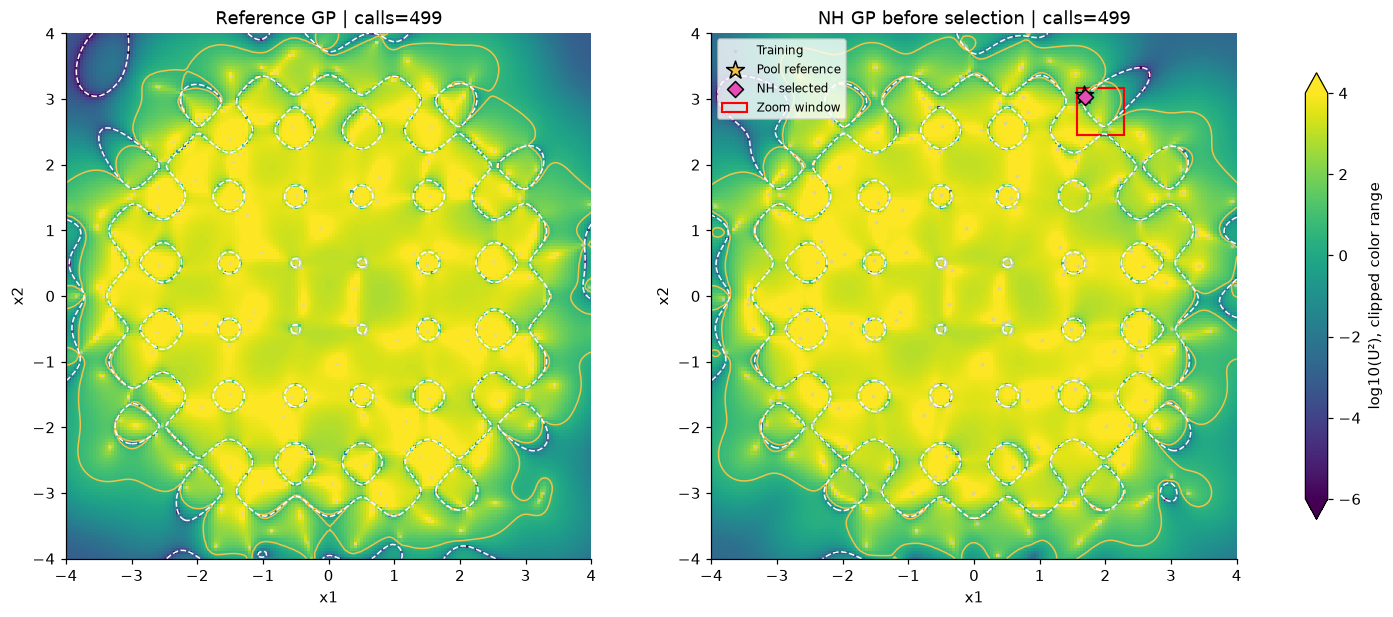

In [5]:
ref_rows = [r for r in runs["reference"]["evaluations"] if r["n_true_calls"] == len(X)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
if ref_rows:
    ref_model, ref_X, _ = restore("reference", ref_rows[-1])
    ref_data = field(ref_model, GLOBAL_LIMITS)
    image = draw_field(axes[0], ref_data, f"Reference GP | calls={len(ref_X)}")
    axes[0].scatter(ref_X[:, 0], ref_X[:, 1], s=5, c="lightgray", marker=".", alpha=.5)
else:
    axes[0].text(.5, .5, "No matching reference call count", ha="center", transform=axes[0].transAxes)
image = draw_field(axes[1], global_data, f"NH GP before selection | calls={len(X)}")
markers(axes[1])
from matplotlib.patches import Rectangle
axes[1].add_patch(Rectangle((zoom[0], zoom[2]), zoom[1]-zoom[0], zoom[3]-zoom[2],
                            fill=False, edgecolor="red", lw=1.4, label="Zoom window"))
axes[1].legend(loc="upper left", fontsize=8)
colorbar(fig, image, axes)
finish(fig, "01_global_fields")

## 국소 운동: 힘과 관성
화살표는 `−∇U²`의 **정규화된 방향**만 나타냅니다(크기 비교용 아님).
Hamiltonian 운동은 관성 때문에 U²가 올라가는 쪽으로도 움직입니다. 보존하려는 양은 U² 자체가 아니라
`H = U² + ||p||²/(2m)`이며, energy-tolerance에 따라 step을 수락하거나 거절합니다.

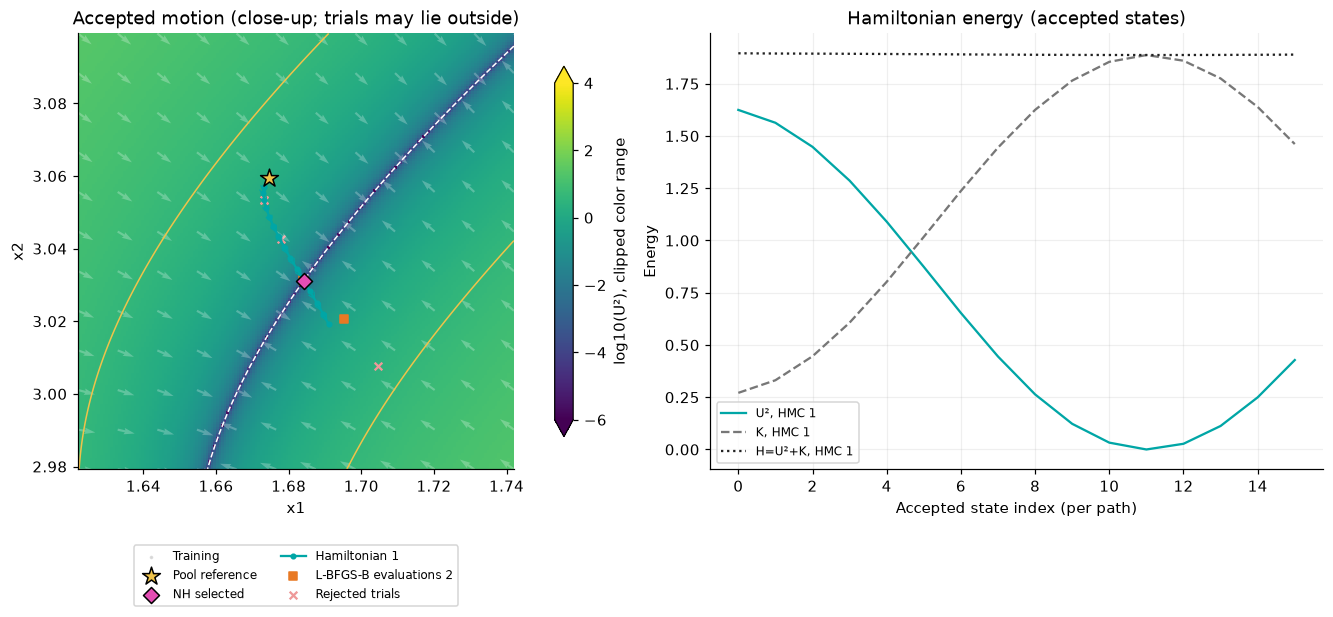

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
image = draw_field(axes[0], tight_data, "Accepted motion (close-up; trials may lie outside)")
markers(axes[0])
draw_paths(axes[0])
gx, gy = np.meshgrid(np.linspace(tight_zoom[0], tight_zoom[1], 12), np.linspace(tight_zoom[2], tight_zoom[3], 12))
gp = np.column_stack([gx.ravel(), gy.ravel()])
force = -np.array([acquisition.energy_gradient(p) for p in gp])
force /= np.maximum(np.linalg.norm(force, axis=1, keepdims=True), 1e-15)
axes[0].quiver(gp[:, 0], gp[:, 1], force[:, 0], force[:, 1], color="white", alpha=.25, scale=25)
axes[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.16), ncol=2)
colorbar(fig, image, axes[0])
for path, events in hmc_paths.items():
    potential = np.array([e["energy"] for e in events])
    kinetic = np.array([e["kinetic"] for e in events])
    axes[1].plot(potential, "-", label=f"U², HMC {path}", color=COLORS["hmc"])
    axes[1].plot(kinetic, "--", label=f"K, HMC {path}", color="#777777")
    axes[1].plot(potential + kinetic, ":", label=f"H=U²+K, HMC {path}", color="#222222")
axes[1].set(xlabel="Accepted state index (per path)", ylabel="Energy", title="Hamiltonian energy (accepted states)")
axes[1].grid(alpha=.2)
axes[1].legend(fontsize=8)
finish(fig, "02_motion_and_energy")

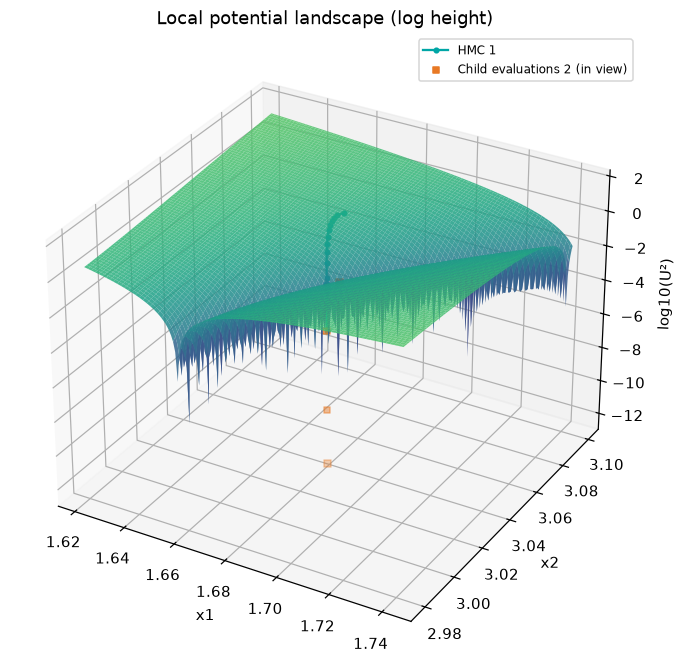

In [7]:
fig = plt.figure(figsize=(10, 6), layout="constrained")
ax = fig.add_subplot(111, projection="3d")
xx, yy, energy, _ = tight_data
height = np.log10(np.maximum(energy, 1e-12))
ax.plot_surface(xx, yy, height, cmap="viridis", norm=norm, alpha=.85, rcount=85, ccount=85)
for path, events in hmc_paths.items():
    points = np.array([e["x"] for e in events])
    z = np.log10(np.maximum([e["energy"] for e in events], 1e-12))
    ax.plot(points[:, 0], points[:, 1], z, "-o", color=COLORS["hmc"], ms=3, label=f"HMC {path}")
for path, events in child_paths.items():
    points = np.array([e["x"] for e in events])
    z = np.log10(np.maximum([e["energy"] for e in events], 1e-12))
    inside = (points[:, 0] >= tight_zoom[0]) & (points[:, 0] <= tight_zoom[1]) & (points[:, 1] >= tight_zoom[2]) & (points[:, 1] <= tight_zoom[3])
    ax.scatter(points[inside, 0], points[inside, 1], z[inside], color=COLORS["child"], marker="s", s=20, label=f"Child evaluations {path} (in view)")
ax.set(xlabel="x1", ylabel="x2", zlabel="log10(U²)", title="Local potential landscape (log height)")
ax.legend(fontsize=8)
finish(fig, "03_local_surface")

## 이동 애니메이션
▶ 재생 또는 슬라이더로 계산 순서를 봅니다. Hamiltonian은 수락된 위치만 연결하고, child는 평가점을 사각형으로 표시합니다.
거절된 trial은 앞의 정적 그림에 표시합니다. 프레임 간격은 표시용이며 물리적 시간 간격이 아닙니다.

In [8]:
if MAKE_ANIMATION:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), layout="constrained")
    for ax, data, title in zip(axes, (local_data, tight_data), ("All evaluated positions", "Accepted-motion close-up")):
        image = draw_field(ax, data, title)
        markers(ax)
    colorbar(fig, image, axes)
    lines = {(panel, path): ax.plot([], [], "-o", color=COLORS["hmc"], ms=3)[0] for panel, ax in enumerate(axes) for path in hmc_paths}
    child_dots = [ax.scatter([], [], c=COLORS["child"], marker="s", s=30) for ax in axes]
    current = [ax.scatter([], [], facecolors="none", edgecolors="white", linewidths=2, s=150, zorder=10) for ax in axes]
    def update(frame):
        visible = events_to_animate[:frame+1]
        for (panel, path), line in lines.items():
            pts = np.array([e["x"] for e in visible if e["path"] == path and e["event"] in ("start", "accepted")]).reshape(-1, 2)
            line.set_data(pts[:, 0], pts[:, 1])
        pts = np.array([e["x"] for e in visible if e["event"] == "child_evaluation"]).reshape(-1, 2)
        for dots in child_dots:
            dots.set_offsets(pts)
        event = visible[-1]
        for dot in current:
            dot.set_offsets(np.array(event["x"]).reshape(1, 2))
        fig.suptitle(f"Replay event {frame+1}/{len(events_to_animate)}: {event['event']} | U²={event['energy']:.3g}")
        return [*lines.values(), *child_dots, *current]
    animation = FuncAnimation(fig, update, frames=len(events_to_animate), interval=350, blit=False, repeat=False)
    animation_html = animation.to_jshtml()
    plt.close(fig)
    display(HTML(animation_html))

## 한 번 관측한 뒤 필드가 어떻게 바뀌는가
선택 시점의 고정 필드와 다음 true-g 관측 후 재학습된 필드를 비교합니다.
다음 모델도 로그에서 복원하며, 새로 true-g 호출을 추가하지 않습니다.
각 그림의 붉은 ×는 **그 시점의 미관측 MC 모집단에서 최소 U인 점**입니다.

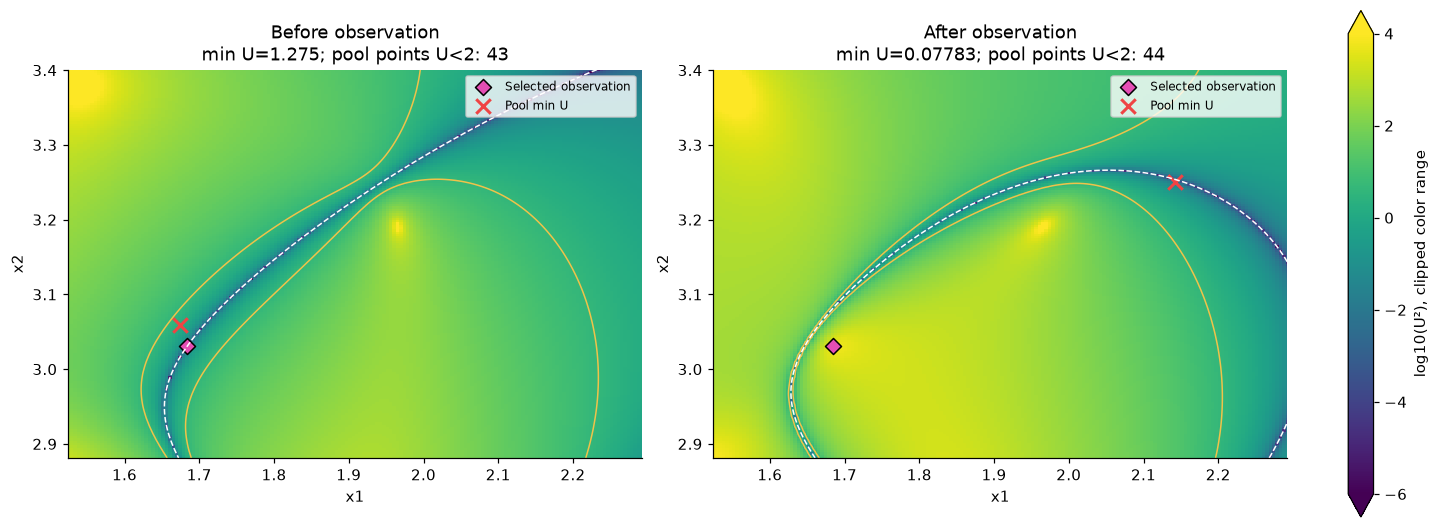

Logged observed g(selected) = 0.869753
Pool min U: 1.27468 -> 0.0778316; U<2 count: 43 -> 44


In [9]:
after_rows = [r for r in runs["nh"]["evaluations"] if r["n_true_calls"] == len(X)+1]
if not after_rows:
    print("다음 관측의 평가 로그가 없어 전후 비교를 생략합니다.")
else:
    after_row = after_rows[0]
    after_model, after_X, _ = restore("nh", after_row)
    def pool_stats(fitted, training, row):
        pts = population("nh", row)
        observed = {tuple(x) for x in training}
        keep = np.array([tuple(x) not in observed for x in pts])
        pts = pts[keep]
        if not len(pts):
            return None, float("inf"), 0
        mu, var = fitted.predict_moments(pts)
        u = np.abs(mu)/np.sqrt(var)
        idx = int(np.argmin(u))
        return pts[idx], float(u[idx]), int(np.sum(u < cfg["evaluation"]["stop"]["min_u"]))
    before_min, before_u, before_count = pool_stats(model, X, before_row)
    after_min, after_u, after_count = pool_stats(after_model, after_X, after_row)
    anchors = np.asarray([x_ref, x_selected] + [p for p in (before_min, after_min) if p is not None])
    lower, upper = anchors.min(axis=0)-.15, anchors.max(axis=0)+.15
    comparison_limits = (lower[0], upper[0], lower[1], upper[1])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
    for ax, fitted, point, u, count, title in [
        (axes[0], model, before_min, before_u, before_count, "Before observation"),
        (axes[1], after_model, after_min, after_u, after_count, "After observation")]:
        image = draw_field(ax, field(fitted, comparison_limits),
                           f"{title}\nmin U={u:.4g}; pool points U<2: {count}")
        ax.scatter(*x_selected, c=COLORS["selected"], marker="D", s=55, edgecolors="black", label="Selected observation")
        if point is not None:
            ax.scatter(*point, c="#ef4444", marker="x", s=90, linewidths=2, label="Pool min U")
        ax.legend(fontsize=8)
    colorbar(fig, image, axes)
    finish(fig, "04_before_after")
    np.testing.assert_allclose(before_u, before_row["population_min_u"], rtol=1e-6, atol=1e-7)
    np.testing.assert_allclose(after_u, after_row["population_min_u"], rtol=1e-6, atol=1e-7)
    print(f"Logged observed g(selected) = {runs['nh']['calls'][len(X)]['y']:.6g}")
    print(f"Pool min U: {before_u:.6g} -> {after_u:.6g}; U<2 count: {before_count} -> {after_count}")

## 그림을 읽는 기준
- 연속 공간에서 U²가 더 낮은 점을 찾는 것과, 관측 후 전체 MC 모집단의 최소 U를 높이는 것은 서로 다른 목표입니다.
- HMC가 골짜기를 건너는지, child가 μ≈0 지점에 모이는지, 선택점 주변의 변화가 다른 MC 점의 불확실성을 어떻게 바꾸는지 확인하세요.
- reference와 NH의 GP는 같은 호출 수에서도 학습 데이터가 다릅니다. 전체 필드 비교는 동일 모델에서 두 탐색기를 비교한 실험이 아닙니다.
- 이 노트북은 경로를 관찰하는 도구입니다. NH 파라미터를 바꾼 실험은 원본 경로 재현 검증과 분리해서 진행해야 합니다.
- PNG는 `artifacts/visualize`에 저장됩니다. 노트북을 재실행하면 그림도 갱신됩니다.